# UTS Data Mining — Tahap 3: Time-Series Clustering Design
**Tema:** Klasterisasi Kondisi Operasional Pompa dari Data Sensor Industrial Multivariat
**Metode:** Window-based Feature Extraction → Scaling → PCA → K-Means / Gaussian Mixture Model (GMM)

**Input:** `sensor_clean_unlabeled.csv` (hasil Tahap 2: 49 sensor, tanpa label, dengan kolom `segment` untuk segmen waktu kontinu)

**Isi notebook (sesuai instruksi Tahap 3):**
1. Merancang algoritma klasterisasi → window, scaling, PCA, K-Means, GMM
2. Merancang optimasi hiperparameter → Elbow (K-Means), BIC/AIC (GMM), pemilihan jumlah komponen PCA, perbandingan scaler & tipe kovarians
3. Menentukan metrik evaluasi internal → Silhouette, Davies-Bouldin, Calinski-Harabasz, BIC, stabilitas antar-inisialisasi

`machine_status` tersedia di sumber asli tetapi tidak masuk ke fitur atau proses fitting. Evaluasi di bawah bersifat internal. Validasi eksternal menggunakan status hanya boleh ditambahkan setelah clustering dan jika diizinkan dosen.

## 0. Setup & Konfigurasi

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import groupby
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# ====== KONFIGURASI GOOGLE DRIVE & COLAB ======
try:
    from google.colab import drive
    if not os.path.exists('/content/drive'):
        drive.mount('/content/drive')
    IN_COLAB = True
    print("[Colab] Google Drive berhasil terhubung.")
except ImportError:
    IN_COLAB = False

# Folder root proyek di Google Drive
DRIVE_PROJECT = Path("/content/drive/MyDrive/Projek Data Mining Kelompok 7")

# Cari file sensor_clean_unlabeled_local.csv hasil dari Tahap 2
DATA_CANDIDATES = [
    DRIVE_PROJECT / "notebook tahap 2" / "output_tahap2" / "sensor_clean_unlabeled_local.csv",
    DRIVE_PROJECT / "notebook tahap 2" / "sensor_clean_unlabeled_local.csv",
    DRIVE_PROJECT / "output_tahap2" / "sensor_clean_unlabeled_local.csv",
    DRIVE_PROJECT / "notebook tahap 3" / "sensor_clean_unlabeled_local.csv",
    DRIVE_PROJECT / "sensor_clean_unlabeled_local.csv",
    Path("/content/sensor_clean_unlabeled_local.csv"),
    Path("output_tahap2/sensor_clean_unlabeled_local.csv"),
    Path("Dataset/sensor_clean_unlabeled_local.csv"),
    Path("sensor_clean_unlabeled_local.csv")
]
DATA_PATH = next((str(p) for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "sensor_clean_unlabeled_local.csv tidak ditemukan! "
        "Pastikan Tahap 2 sudah dijalankan atau file hasil Tahap 2 ada di folder 'notebook tahap 2/output_tahap2'."
    )

# Folder output terpisah khusus untuk Tahap 3
if IN_COLAB and (DRIVE_PROJECT / "notebook tahap 3").exists():
    OUTPUT_DIR = DRIVE_PROJECT / "notebook tahap 3" / "output_tahap3"
elif IN_COLAB and DRIVE_PROJECT.exists():
    OUTPUT_DIR = DRIVE_PROJECT / "output_tahap3"
else:
    OUTPUT_DIR = Path("output_tahap3")

# Buat folder output otomatis jika belum ada
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data Input   : {DATA_PATH}")
print(f"Folder Output: {OUTPUT_DIR.resolve()}")

WINDOW = 60              # panjang window (menit)
STRIDE = 30              # pergeseran window (menit) -> overlap 50%
PCA_VARIANCE = 0.90      # target variansi kumulatif PCA
FEATURE_STATS = ["mean", "std"]   # statistik window yang dipakai (dipilih lewat ablasi, bagian 4)
SCALER = "standard"      # "standard" atau "robust" (dibandingkan di bagian 5)
K_RANGE = list(range(2, 11))
N_INIT = 10
RANDOM_STATE = 42
KMEANS_K_OVERRIDE = None  # None: otomatis dari peringkat metrik K-Means
GMM_K_OVERRIDE = None      # None: otomatis dari BIC GMM; override hanya kalau ada alasan tertulis
SILHOUETTE_SAMPLE_SIZE = 2000  # aproksimasi deterministik agar komputasi lokal terukur

def silhouette_sample(X, labels):
    n = len(X)
    return silhouette_score(X, labels, sample_size=min(SILHOUETTE_SAMPLE_SIZE, n), random_state=RANDOM_STATE)

## 1. Load Data

In [2]:
data = pd.read_csv(DATA_PATH, index_col="timestamp", parse_dates=True)
seg = data["segment"].values
X = data.drop(columns="segment")
sensor_cols = X.columns.tolist()
print(f"Sumber: {Path(DATA_PATH).resolve()}")
print(f"Data: {X.shape[0]:,} baris x {X.shape[1]} sensor | segmen kontinu: {len(np.unique(seg))}")
assert "machine_status" not in X.columns
expected = (209548, 49, 7)
actual = (len(X), X.shape[1], len(np.unique(seg)))
if actual != expected:
    raise ValueError(f"Input tidak cocok dengan keluaran Tahap 2 yang diharapkan {expected}; terbaca {actual}. Jalankan ulang Tahap 2 dan periksa DATA_PATH." )
print("Pemeriksaan input Tahap 2: lolos (209.548 baris, 49 sensor, 7 segmen).")
X.head(3)

Sumber: C:\KULIAH\SEMESTER 5\Data mining\UTS Data Mining\Dataset\sensor_clean_unlabeled_local.csv
Data: 209,548 baris x 49 sensor | segmen kontinu: 7
Pemeriksaan input Tahap 2: lolos (209.548 baris, 49 sensor, 7 segmen).


                     sensor_00  sensor_01  ...  sensor_48  sensor_49
timestamp                                  ...                      
2018-04-01 00:00:00   2.465394   47.09201  ...   157.9861   67.70834
2018-04-01 00:01:00   2.465394   47.09201  ...   157.9861   67.70834
2018-04-01 00:02:00   2.444734   47.35243  ...   155.9606   67.12963

[3 rows x 49 columns]

## 2. Rancangan Algoritma (1/5): Window-based Feature Extraction
Data per-menit tidak independen (autokorelasi lag-1 ≈ 0,996 di Tahap 2). Maka satu **window** berdurasi $W$ menit diringkas menjadi satu vektor fitur sehingga ketergantungan temporal lokal ikut terekam. Untuk setiap sensor $s$ dalam window $x_1,\dots,x_W$:

| Fitur | Rumus | Makna operasional |
|---|---|---|
| mean | $\bar{x}=\frac{1}{W}\sum x_t$ | level operasi |
| std | $\sqrt{\frac{1}{W}\sum (x_t-\bar{x})^2}$ | tingkat fluktuasi |
| min, max | $\min x_t,\ \max x_t$ | rentang/ekstrem dalam window |
| slope | $\frac{\sum (t-\bar{t})(x_t-\bar{x})}{\sum (t-\bar{t})^2}$ | tren naik/turun |

Total **kandidat** fitur = 49 sensor × 5 statistik = 245 fitur per window. Himpunan fitur yang benar-benar dipakai ditentukan lewat ablasi di bagian 4, bukan ditebak. Window dibentuk **di dalam tiap segmen kontinu**, sehingga tidak ada window yang melintasi gap waktu hasil pembersihan Tahap 2.

In [3]:
STATS = ["mean", "std", "min", "max", "slope"]

def extract_windows(X, seg, window, stride):
    t = np.arange(window) - (window - 1) / 2
    denom = (t ** 2).sum()
    feats, meta = [], []
    for sid in np.unique(seg):
        m = seg == sid
        arr, idx = X.values[m], X.index[m]
        if len(arr) < window:
            continue
        w = sliding_window_view(arr, window, axis=0)[::stride]   # (n_win, n_sensor, window)
        f = np.hstack([w.mean(2), w.std(2), w.min(2), w.max(2), (w @ t) / denom])
        starts = np.arange(0, len(arr) - window + 1, stride)
        feats.append(f)
        meta.append(pd.DataFrame({"segment": sid, "start": idx[starts], "end": idx[starts + window - 1]}))
    cols = [f"{s}__{st}" for st in STATS for s in X.columns]
    return pd.DataFrame(np.vstack(feats), columns=cols), pd.concat(meta, ignore_index=True)

F, meta = extract_windows(X, seg, WINDOW, STRIDE)
print(f"Jumlah window : {len(F):,}")
print(f"Jumlah fitur  : {F.shape[1]}  ({len(sensor_cols)} sensor x {len(STATS)} statistik)")
print("Segmen input:", sorted(np.unique(seg).tolist()))
print("Segmen yang menghasilkan window:", meta['segment'].value_counts().sort_index().to_dict())
missing_segments = sorted(set(np.unique(seg)) - set(meta['segment'].unique()))
print("Segmen tanpa window (lebih pendek dari window):", missing_segments)
assert F.isna().sum().sum() == 0
F.iloc[:3, :6]

Jumlah window : 6,975
Jumlah fitur  : 245  (49 sensor x 5 statistik)
Segmen input: [0, 1, 2, 3, 4, 5, 6]
Segmen yang menghasilkan window: {0: 573, 1: 215, 2: 877, 3: 520, 4: 1948, 5: 1109, 6: 1733}
Segmen tanpa window (lebih pendek dari window): []


   sensor_00__mean  sensor_01__mean  ...  sensor_04__mean  sensor_05__mean
0         2.454506        48.556132  ...       634.120408        75.736439
1         2.454490        48.345629  ...       633.865780        74.522699
2         2.454244        48.015768  ...       634.236105        74.565887

[3 rows x 6 columns]

## 3. Rancangan Algoritma (2/5): Scaling
Bukti Tahap 2: rasio std antar-sensor ≈ 759× dan 42 dari 49 sensor sangat miring. Di bawah ini ditunjukkan dampaknya langsung pada PCA: tanpa scaling, komponen utama didominasi sensor berskala besar.

In [4]:
mean_cols = [c for c in F.columns if c.endswith("__mean")]

p_raw = PCA(n_components=3).fit(F[mean_cols])
p_std = PCA(n_components=3).fit(StandardScaler().fit_transform(F[mean_cols]))

load_raw = pd.Series(np.abs(p_raw.components_[0]), index=[c.split("__")[0] for c in mean_cols]).sort_values(ascending=False)
print(f"[TANPA scaling] PC1 menjelaskan {p_raw.explained_variance_ratio_[0]*100:.1f}% variansi")
print("  Sensor dengan loading PC1 terbesar:", load_raw.head(3).round(3).to_dict())
print(f"[DENGAN scaling] PC1 menjelaskan {p_std.explained_variance_ratio_[0]*100:.1f}% variansi (kontribusi sensor lebih merata)")

[TANPA scaling] PC1 menjelaskan 77.6% variansi
  Sensor dengan loading PC1 terbesar: {'sensor_23': 0.341, 'sensor_28': 0.317, 'sensor_31': 0.295}
[DENGAN scaling] PC1 menjelaskan 36.7% variansi (kontribusi sensor lebih merata)


Dua kandidat scaler: `StandardScaler` (mean–std) dan `RobustScaler` (median–IQR). Hasil scaling dipangkas ke ±`CLIP` (winsorizing) agar nilai ekstrem tidak mendominasi jarak. Fungsi `prep()` di bawah menjalankan alur scaling → clip → PCA untuk himpunan fitur dan scaler tertentu.

In [5]:
CLIP = 5.0   # winsorizing pasca-scaling; None untuk menonaktifkan

def scale(Fm, kind="standard", clip=CLIP):
    sc = RobustScaler() if kind == "robust" else StandardScaler()
    Zs = sc.fit_transform(Fm)
    return np.clip(Zs, -clip, clip) if clip else Zs

def prep(cols, kind="standard", var=PCA_VARIANCE):
    Fm = F[cols]
    Fm = Fm.loc[:, Fm.std() > 0]                 # buang fitur konstan
    Zs = scale(Fm, kind)
    cum = np.cumsum(PCA(random_state=RANDOM_STATE).fit(Zs).explained_variance_ratio_)
    k = int(np.argmax(cum >= var) + 1)           # jumlah komponen otomatis
    return PCA(n_components=k, random_state=RANDOM_STATE).fit_transform(Zs), cum, k

def cols_of(stats):
    return [f"{s}__{st}" for st in stats for s in sensor_cols]

## 4. Optimasi Hiperparameter (1/4): Ablasi Himpunan Fitur Window
Himpunan statistik window yang dipakai tidak ditentukan sepihak, melainkan dibandingkan secara empiris: tiap himpunan di-scaling, direduksi PCA, lalu di-K-Means pada beberapa $k$ dan dinilai dengan Silhouette dari sampel tetap hingga 2.000 window.

*Catatan membaca tabel:* Silhouette dihitung di ruang PCA berdimensi berbeda sehingga tidak sepenuhnya sebanding, dan himpunan fitur yang lebih kecil cenderung menghasilkan Silhouette lebih tinggi hanya karena dimensinya lebih rendah. Pada hasil lokal terbaru, `mean` saja memperoleh Silhouette lebih tinggi daripada `mean+std` pada k=2–5. Karena itu, `mean+std` dipilih sebagai rancangan yang juga membawa informasi fluktuasi, bukan karena pemisahan clusternya lebih baik. Laporkan trade-off ini dan gunakan tabel ablasi sebagai bukti.

In [6]:
FEATURE_SETS = {
    "mean": ["mean"],
    "mean+std": ["mean", "std"],
    "mean+std+slope": ["mean", "std", "slope"],
    "mean+std+min+max": ["mean", "std", "min", "max"],
    "semua (5 statistik)": STATS,
}
abl = []
for name, stats in FEATURE_SETS.items():
    Zs, _, kp = prep(cols_of(stats), "standard")
    row = {"fitur": name, "n_fitur": len(stats) * len(sensor_cols), "n_PC_90%": kp}
    for k in (2, 3, 4, 5):
        row[f"sil_k{k}"] = silhouette_sample(Zs, KMeans(k, n_init=5, random_state=RANDOM_STATE).fit_predict(Zs))
    abl.append(row)
abl = pd.DataFrame(abl).set_index("fitur")
display(abl.round(3))

                     n_fitur  n_PC_90%  sil_k2  sil_k3  sil_k4  sil_k5
fitur                                                                 
mean                      49        13   0.589   0.608   0.297   0.251
mean+std                  98        31   0.481   0.494   0.200   0.141
mean+std+slope           147        55   0.408   0.415   0.144   0.149
mean+std+min+max         196        29   0.532   0.548   0.228   0.233
semua (5 statistik)      245        50   0.491   0.505   0.188   0.193


## 5. Reduksi Dimensi dengan PCA & Pemilihan Scaler (2/4)
Fitur window sangat berkorelasi (Tahap 2: banyak pasangan sensor $|r|\ge0{,}9$). PCA memproyeksikan data ke komponen ortogonal $Z = X_{s} W_{k}$ dan **jumlah komponen dipilih otomatis** sebagai $k$ terkecil dengan variansi kumulatif ≥ `PCA_VARIANCE`. Manfaat: menghilangkan multikolinearitas dan menekan *curse of dimensionality* sebelum jarak/kepadatan dihitung.

Pada himpunan fitur terpilih (`FEATURE_STATS`), kedua scaler dibandingkan.

Fitur window dipakai: ['mean', 'std'] -> 98 fitur
RobustScaler   -> 36 komponen untuk 90% variansi
StandardScaler -> 31 komponen untuk 90% variansi
    RobustScaler  StandardScaler
2          0.389           0.481
3          0.371           0.494
4          0.312           0.200
5          0.155           0.141
6          0.160           0.170
7          0.163           0.166
8          0.163           0.169
9          0.145           0.168
10         0.138           0.167


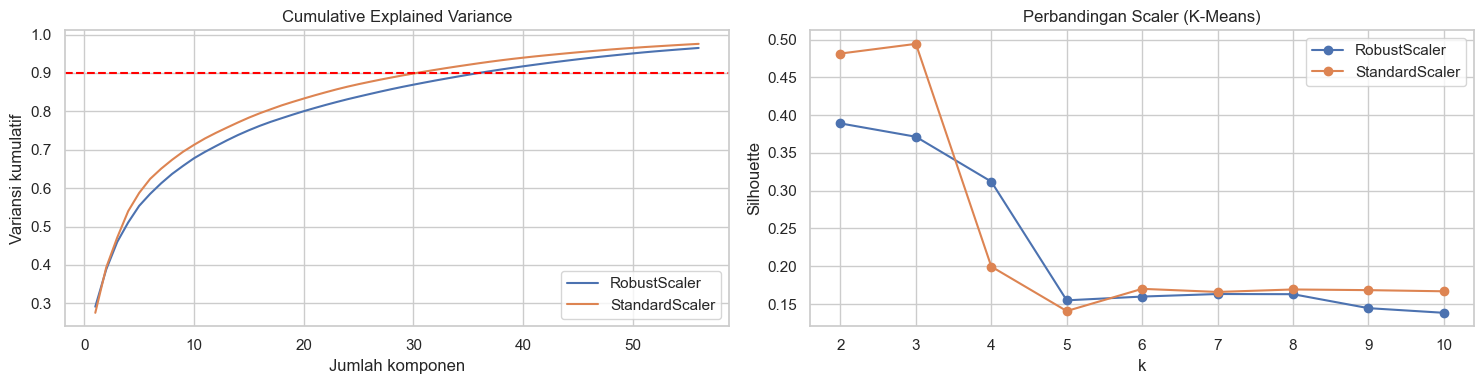

In [7]:
sel_cols = cols_of(FEATURE_STATS)
print("Fitur window dipakai:", FEATURE_STATS, f"-> {len(sel_cols)} fitur")

Z_robust, cum_r, k_r = prep(sel_cols, "robust")
Z_standard, cum_s, k_s = prep(sel_cols, "standard")
print(f"RobustScaler   -> {k_r} komponen untuk {PCA_VARIANCE*100:.0f}% variansi")
print(f"StandardScaler -> {k_s} komponen untuk {PCA_VARIANCE*100:.0f}% variansi")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
n_show = max(k_r, k_s) + 20
ax[0].plot(range(1, n_show + 1), cum_r[:n_show], label="RobustScaler")
ax[0].plot(range(1, n_show + 1), cum_s[:n_show], label="StandardScaler")
ax[0].axhline(PCA_VARIANCE, color="red", ls="--")
ax[0].set_xlabel("Jumlah komponen"); ax[0].set_ylabel("Variansi kumulatif"); ax[0].set_title("Cumulative Explained Variance"); ax[0].legend()

scaler_cmp = {}
for name, Zs in [("RobustScaler", Z_robust), ("StandardScaler", Z_standard)]:
    sil = [silhouette_sample(Zs, KMeans(k, n_init=5, random_state=RANDOM_STATE).fit_predict(Zs)) for k in K_RANGE]
    scaler_cmp[name] = sil
    ax[1].plot(K_RANGE, sil, marker="o", label=name)
ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette"); ax[1].set_title("Perbandingan Scaler (K-Means)"); ax[1].legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame(scaler_cmp, index=K_RANGE).round(3))

Scaler untuk langkah selanjutnya ditentukan oleh `SCALER` di sel konfigurasi. Default `standard`; ubah ke `robust` bila perbandingan di atas di datamu mendukungnya.

In [8]:
Z = Z_robust if SCALER == "robust" else Z_standard
print(f"Scaler dipakai: {SCALER} | Ruang klaster: {Z.shape[0]:,} window x {Z.shape[1]} komponen PCA")

Scaler dipakai: standard | Ruang klaster: 6,975 window x 31 komponen PCA


## 6. Rancangan Algoritma (4/5) & Optimasi (3/4): K-Means
**Formulasi.** K-Means meminimalkan jumlah kuadrat jarak ke centroid (inertia):
$$J=\sum_{j=1}^{k}\sum_{z_i\in C_j}\lVert z_i-\mu_j\rVert^2$$
**Optimasi $k$:** Elbow Method (titik tikungan kurva inertia, dicari otomatis sebagai titik terjauh dari garis lurus ujung-ke-ujung), dikonfirmasi dengan Silhouette, Davies-Bouldin, dan Calinski-Harabasz.

       inertia  silhouette  davies_bouldin  calinski_harabasz
k                                                            
2   304048.566       0.481           0.850           2729.032
3   265972.704       0.494           1.176           2058.678
4   237339.112       0.200           1.650           1818.148
5   225271.408       0.160           1.849           1529.797
6   200199.220       0.170           1.658           1551.463
7   190243.283       0.175           1.682           1421.127
8   181800.287       0.169           1.758           1320.718
9   176492.192       0.168           1.755           1216.403
10  171630.021       0.167           1.791           1133.641

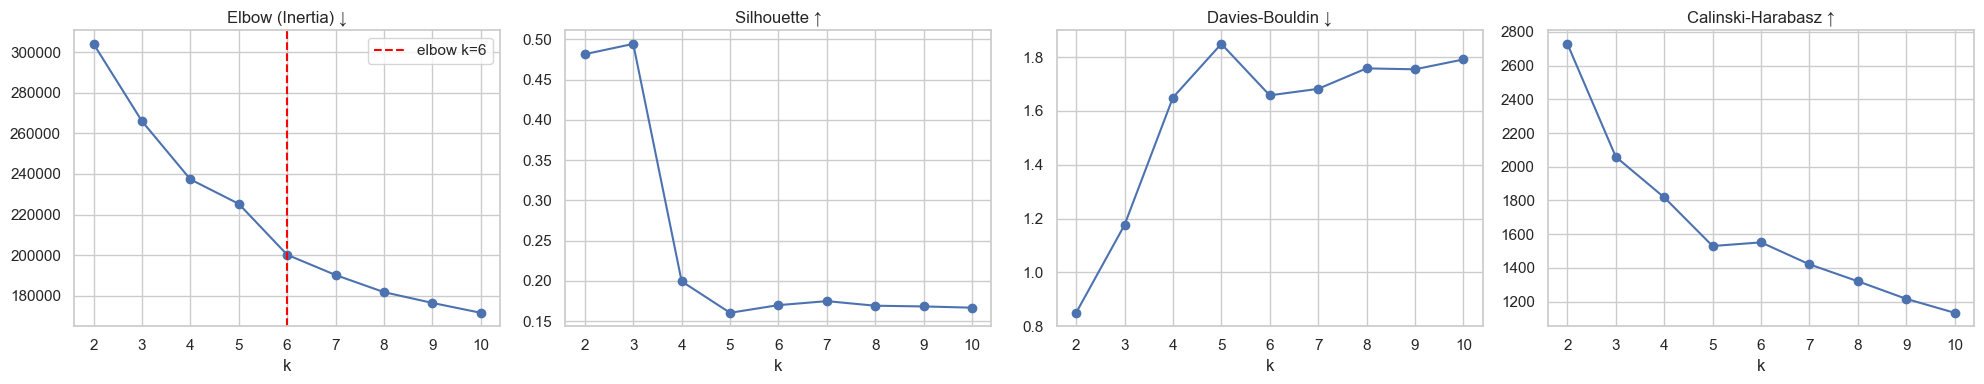

In [9]:
rows = []
for k in K_RANGE:
    km = KMeans(k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z)
    rows.append(dict(k=k, inertia=km.inertia_,
                     silhouette=silhouette_sample(Z, km.labels_),
                     davies_bouldin=davies_bouldin_score(Z, km.labels_),
                     calinski_harabasz=calinski_harabasz_score(Z, km.labels_)))
km_res = pd.DataFrame(rows).set_index("k")

def elbow_k(ks, vals):
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.array(vals) - min(vals)) / (max(vals) - min(vals))
    d = np.abs((y[-1] - y[0]) * x - y + y[0]) / np.sqrt((y[-1] - y[0]) ** 2 + 1)
    return ks[int(np.argmax(d))]

k_elbow = elbow_k(K_RANGE, km_res["inertia"].values)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, (col, title) in zip(ax, [("inertia", "Elbow (Inertia) ↓"), ("silhouette", "Silhouette ↑"),
                                ("davies_bouldin", "Davies-Bouldin ↓"), ("calinski_harabasz", "Calinski-Harabasz ↑")]):
    a.plot(K_RANGE, km_res[col], marker="o"); a.set_title(title); a.set_xlabel("k")
ax[0].axvline(k_elbow, color="red", ls="--", label=f"elbow k={k_elbow}"); ax[0].legend()
plt.tight_layout(); plt.show()
km_res.round(3)

## 7. Rancangan Algoritma (5/5) & Optimasi (4/4): GMM
**Formulasi.** GMM memodelkan data sebagai campuran $k$ distribusi Gaussian:
$$p(z)=\sum_{j=1}^{k}\pi_j\,\mathcal{N}(z\mid\mu_j,\Sigma_j)$$
dilatih dengan algoritma EM. Berbeda dari K-Means, GMM memberi **soft assignment** (probabilitas keanggotaan) dan mampu menangkap klaster **elips/tumpang-tindih** karena $\Sigma_j$ bebas.

**Optimasi:** jumlah komponen $k$ dan tipe kovarians (`full`, `tied`, `diag`, `spherical`) dipilih dengan **BIC** (semakin kecil semakin baik):
$$\text{BIC}=p\ln n-2\ln\hat{L}$$

BIC minimum: cov='full', k=10


cov      diag      full  spherical      tied
k                                           
2    557627.0  497831.0   652262.0  601902.0
3    540385.0  471351.0   613346.0  587183.0
4    526259.0  438779.0   586967.0  580983.0
5    517188.0  424218.0   573467.0  576573.0
6    509277.0  406797.0   559199.0  567071.0
7    506952.0  403530.0   554891.0  561781.0
8    502464.0  401050.0   546920.0  555532.0
9    496556.0  393791.0   540949.0  551655.0
10   492016.0  392976.0   537402.0  549085.0

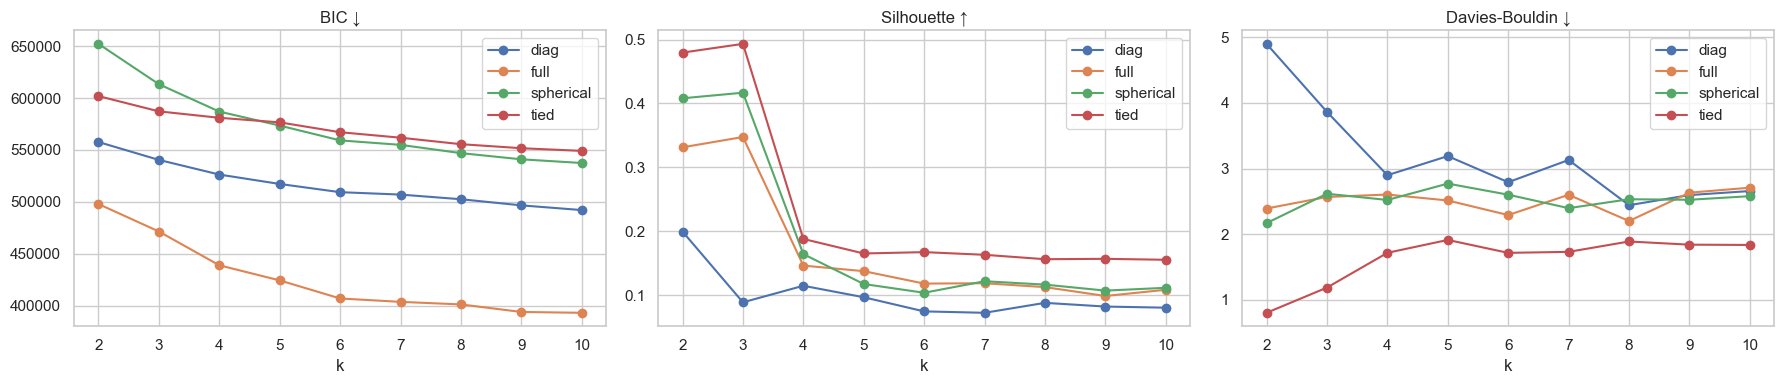

In [10]:
rows = []
for cov in ["full", "tied", "diag", "spherical"]:
    for k in K_RANGE:
        gm = GaussianMixture(k, covariance_type=cov, n_init=3, reg_covar=1e-4, random_state=RANDOM_STATE).fit(Z)
        lab = gm.predict(Z)
        rows.append(dict(cov=cov, k=k, bic=gm.bic(Z), aic=gm.aic(Z),
                         silhouette=silhouette_sample(Z, lab) if len(set(lab)) > 1 else np.nan,
                         davies_bouldin=davies_bouldin_score(Z, lab) if len(set(lab)) > 1 else np.nan))
gm_res = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for cov, g in gm_res.groupby("cov"):
    ax[0].plot(g["k"], g["bic"], marker="o", label=cov)
    ax[1].plot(g["k"], g["silhouette"], marker="o", label=cov)
    ax[2].plot(g["k"], g["davies_bouldin"], marker="o", label=cov)
for a, t in zip(ax, ["BIC ↓", "Silhouette ↑", "Davies-Bouldin ↓"]):
    a.set_title(t); a.set_xlabel("k"); a.legend()
plt.tight_layout(); plt.show()

best = gm_res.loc[gm_res["bic"].idxmin()]
print(f"BIC minimum: cov='{best['cov']}', k={int(best['k'])}")
gm_res.pivot(index="k", columns="cov", values="bic").round(0)

**Catatan interpretasi BIC.** Window dengan overlap 50% saling berkorelasi, sehingga asumsi sampel independen pada BIC tidak sepenuhnya terpenuhi dan BIC cenderung terus turun saat $k$ naik. Karena itu, BIC GMM dipilih secara terpisah dari K-Means dan dibaca bersama grafik serta analisis stride. Minimum di batas rentang menandakan rentang K perlu diperluas atau hasil belum konklusif. BIC antar-stride tidak dibandingkan langsung karena jumlah dan ketergantungan sampel berbeda.

## 8. Penentuan Jumlah Klaster Final
Jumlah cluster dipilih **terpisah per algoritma**. K-Means memakai rata-rata peringkat Silhouette, Davies-Bouldin, dan Calinski-Harabasz. GMM dipindai dengan BIC pada beberapa jumlah komponen dan tipe kovarians. Jika minimum BIC jatuh di batas rentang, jumlah komponen GMM belum terselesaikan. Untuk membandingkan bentuk algoritma secara setara, GMM kemudian dievaluasi pada K yang sama dengan K-Means; hasil itu bukan klaim bahwa K tersebut optimal bagi GMM.

In [11]:
rank = pd.DataFrame({
    "silhouette": km_res["silhouette"].rank(ascending=False),
    "davies_bouldin": km_res["davies_bouldin"].rank(ascending=True),
    "calinski_harabasz": km_res["calinski_harabasz"].rank(ascending=False),
})
rank["rata_rata_rank"] = rank.mean(axis=1)
k_rank = int(rank["rata_rata_rank"].idxmin())
K_KMEANS = int(KMEANS_K_OVERRIDE) if KMEANS_K_OVERRIDE else k_rank

best_gmm_row = gm_res.loc[gm_res["bic"].idxmin()]
K_GMM_BIC = int(best_gmm_row["k"])
COV_GMM_BIC = str(best_gmm_row["cov"])
if GMM_K_OVERRIDE:
    K_GMM = int(GMM_K_OVERRIDE)
    GMM_COV = str(gm_res.loc[gm_res["k"] == K_GMM].sort_values("bic").iloc[0]["cov"])
    GMM_COMPARISON_NOTE = "K ditetapkan manual; nyatakan alasan dan tetap laporkan hasil BIC."
elif K_GMM_BIC in (min(K_RANGE), max(K_RANGE)):
    # BIC did not identify an interior optimum. Use matched K only for algorithm comparison.
    K_GMM = K_KMEANS
    GMM_COV = str(gm_res.loc[gm_res["k"] == K_GMM].sort_values("bic").iloc[0]["cov"])
    GMM_COMPARISON_NOTE = "BIC minimum di batas rentang; GMM K ini hanya pembanding same-K, bukan K optimum."
else:
    K_GMM, GMM_COV = K_GMM_BIC, COV_GMM_BIC
    GMM_COMPARISON_NOTE = "BIC menemukan minimum di dalam rentang uji."

print(rank.sort_values("rata_rata_rank").head(5))
print(f"\nK-Means: K={K_KMEANS} dari konsensus peringkat")
print(f"GMM BIC scan: minimum K={K_GMM_BIC}, covariance='{COV_GMM_BIC}'")
if K_GMM_BIC in (min(K_RANGE), max(K_RANGE)):
    print("PERINGATAN: minimum BIC berada di batas rentang; belum ada K optimum GMM yang teridentifikasi.")
print(f"GMM yang difit: K={K_GMM}, covariance='{GMM_COV}'. {GMM_COMPARISON_NOTE}")


   silhouette  davies_bouldin  calinski_harabasz  rata_rata_rank
k                                                               
2         2.0             1.0                1.0        1.333333
3         1.0             2.0                2.0        1.666667
4         3.0             3.0                3.0        3.000000
6         5.0             4.0                4.0        4.333333
7         4.0             5.0                6.0        5.000000

K-Means: K=2 dari konsensus peringkat
GMM BIC scan: minimum K=10, covariance='full'
PERINGATAN: minimum BIC berada di batas rentang; belum ada K optimum GMM yang teridentifikasi.
GMM yang difit: K=2, covariance='full'. BIC minimum di batas rentang; GMM K ini hanya pembanding same-K, bukan K optimum.


## 9. Pemodelan Final & Evaluasi Internal

In [12]:
km = KMeans(K_KMEANS, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z)
gm = GaussianMixture(K_GMM, covariance_type=GMM_COV, n_init=10, reg_covar=1e-4, random_state=RANDOM_STATE).fit(Z)
lab_km = km.labels_
lab_gm = gm.predict(Z)
conf_gm = gm.predict_proba(Z).max(axis=1)

def metrics(lab):
    return dict(Silhouette=silhouette_sample(Z, lab), Davies_Bouldin=davies_bouldin_score(Z, lab),
                Calinski_Harabasz=calinski_harabasz_score(Z, lab))

# Stabilitas ARI dibandingkan model acuan yang memakai beberapa inisialisasi.
def stability(make, ref, n=10):
    return [adjusted_rand_score(ref, make(s)) for s in range(n)]
st_km = stability(lambda s: KMeans(K_KMEANS, n_init=1, random_state=s).fit_predict(Z), lab_km)
st_gm = stability(lambda s: GaussianMixture(K_GMM, covariance_type=GMM_COV, n_init=1, reg_covar=1e-4, random_state=s).fit(Z).predict(Z), lab_gm)

res = pd.DataFrame({"K-Means": metrics(lab_km), "GMM": metrics(lab_gm)}).T
res["K"] = [K_KMEANS, K_GMM]
res["Stabilitas ARI (mean)"] = [np.mean(st_km), np.mean(st_gm)]
res["Stabilitas ARI (std)"] = [np.std(st_km), np.std(st_gm)]
res["BIC"] = [np.nan, gm.bic(Z)]
print(f"K-Means K={K_KMEANS} | GMM K={K_GMM} cov='{GMM_COV}' | PCA={Z.shape[1]} komponen | window={WINDOW} menit, stride={STRIDE} menit")
display(res.round(3))
print(f"Kesepakatan K-Means vs GMM (ARI antar-dua-metode): {adjusted_rand_score(lab_km, lab_gm):.3f}")


K-Means K=2 | GMM K=2 cov='full' | PCA=31 komponen | window=60 menit, stride=30 menit
         Silhouette  Davies_Bouldin  ...  Stabilitas ARI (std)         BIC
K-Means       0.481           0.850  ...                 0.001         NaN
GMM           0.331           2.391  ...                 0.000  497831.006

[2 rows x 7 columns]
Kesepakatan K-Means vs GMM (ARI antar-dua-metode): 0.404


## 10. Visualisasi Klaster

Window GMM dengan keyakinan < 0.9 (zona tumpang-tindih): 1.2%


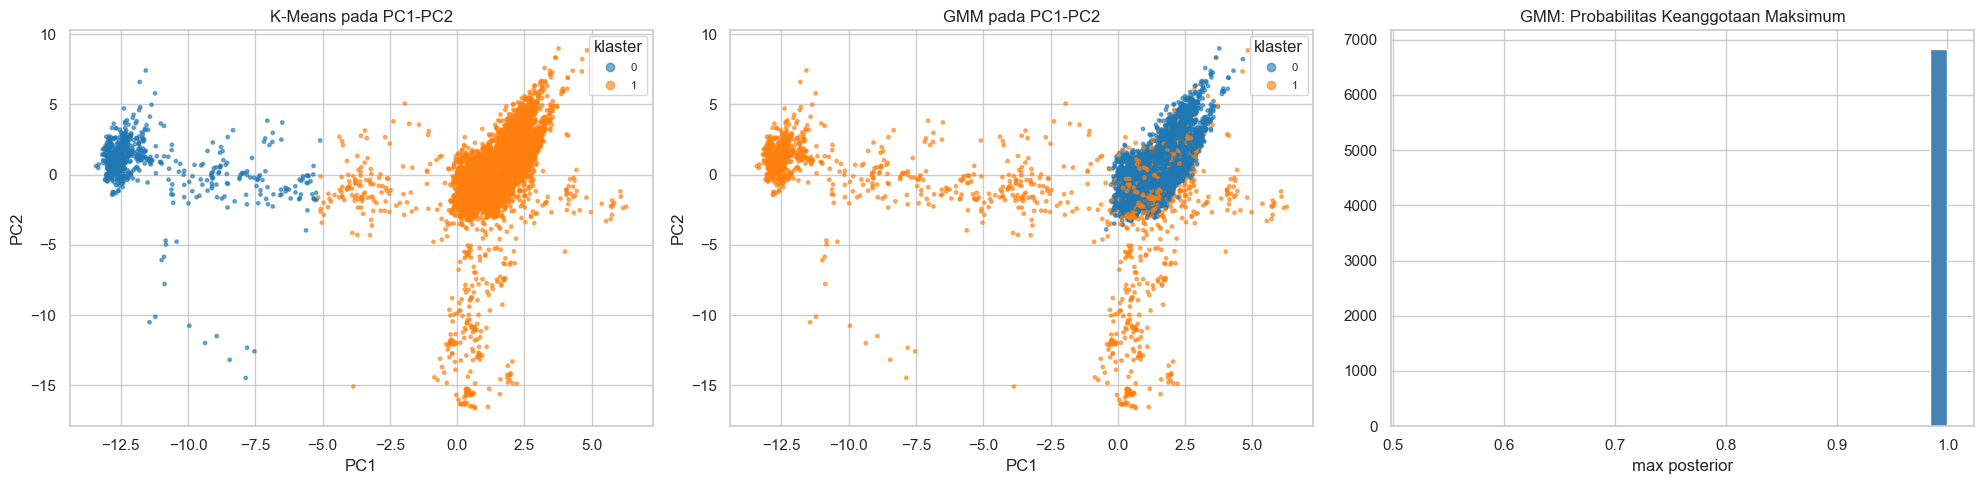

In [13]:
PAL = dict(cmap="tab10", vmin=0, vmax=9)
pc = Z[:, :2]
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, lab, t in [(ax[0], lab_km, "K-Means"), (ax[1], lab_gm, "GMM")]:
    sc = a.scatter(pc[:, 0], pc[:, 1], c=lab, s=6, alpha=0.6, **PAL)
    a.set_title(f"{t} pada PC1-PC2"); a.set_xlabel("PC1"); a.set_ylabel("PC2")
    a.legend(*sc.legend_elements(), title="klaster", loc="best", fontsize=8)
ax[2].hist(conf_gm, bins=30, color="steelblue")
ax[2].set_title("GMM: Probabilitas Keanggotaan Maksimum"); ax[2].set_xlabel("max posterior")
plt.tight_layout(); plt.show()
print(f"Window GMM dengan keyakinan < 0.9 (zona tumpang-tindih): {(conf_gm < 0.9).mean()*100:.1f}%")

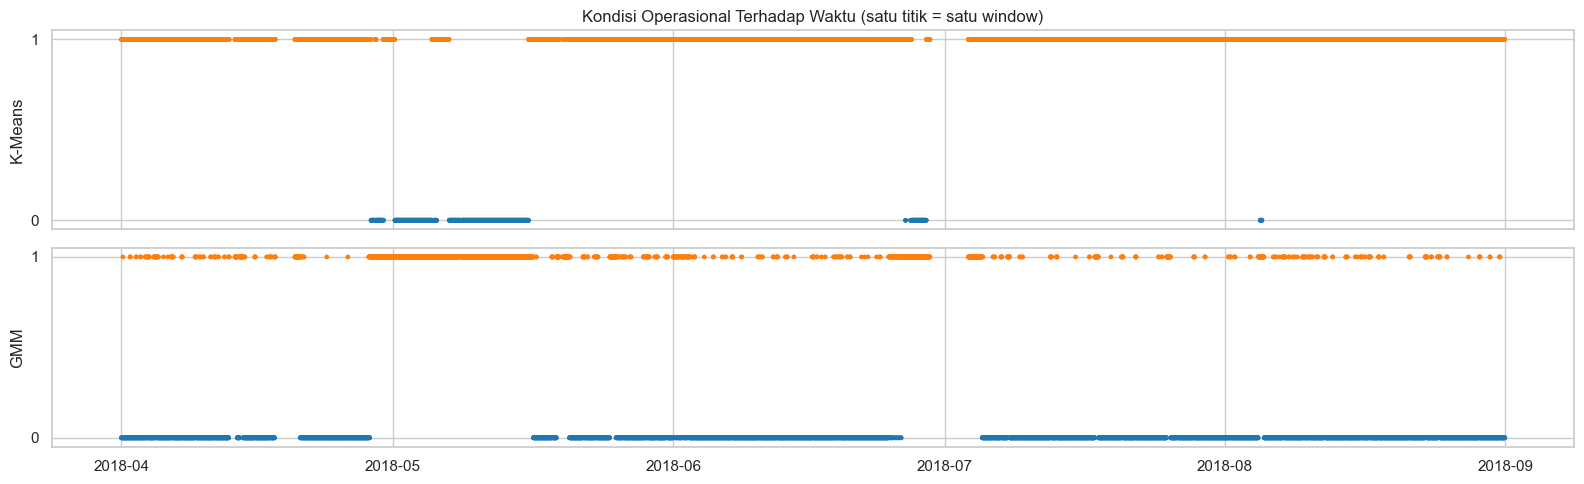

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(16, 5), sharex=True)
for a, lab, k, t in [(ax[0], lab_km, K_KMEANS, "K-Means"), (ax[1], lab_gm, K_GMM, "GMM")]:
    a.scatter(meta["start"], lab, c=lab, s=6, **PAL)
    a.set_yticks(range(k)); a.set_ylabel(t)
ax[0].set_title("Kondisi Operasional Terhadap Waktu (satu titik = satu window)")
plt.tight_layout(); plt.show()

## 11. Karakteristik Temporal Hasil Klaster
Klaster yang bermakna sebagai *kondisi operasional* seharusnya **bertahan beberapa saat**, bukan berganti acak tiap window. Persistensi dibandingkan dengan baseline acak (label diacak urutannya). 

In [15]:
seg_w = meta["segment"].values

def persistence(lab):
    same = [(lab[seg_w == s][1:] == lab[seg_w == s][:-1]) for s in np.unique(seg_w)]
    return np.concatenate(same).mean()

def run_lengths(lab):
    out = []
    for s in np.unique(seg_w):
        out += [(k, len(list(g))) for k, g in groupby(lab[seg_w == s])]
    return pd.DataFrame(out, columns=["klaster", "panjang_run"])

rows = []
for name, lab in [("K-Means", lab_km), ("GMM", lab_gm)]:
    p = np.bincount(lab) / len(lab)
    rows.append(dict(metode=name, persistensi=persistence(lab), baseline_acak=(p ** 2).sum(),
                     jumlah_transisi=int(len(run_lengths(lab)) - len(np.unique(seg_w)))))
display(pd.DataFrame(rows).set_index("metode").round(3))

rl = run_lengths(lab_km).groupby("klaster")["panjang_run"].agg(["count", "median", "max"])
rl.columns = ["jumlah_run", "median_run_(window)", "run_terpanjang_(window)"]
print("K-Means, lama bertahan per klaster (1 window = %d menit pergeseran):" % STRIDE)
display(rl)

         persistensi  baseline_acak  jumlah_transisi
metode                                              
K-Means        0.997          0.803               22
GMM            0.937          0.613              436
K-Means, lama bertahan per klaster (1 window = 30 menit pergeseran):
         jumlah_run  median_run_(window)  run_terpanjang_(window)
klaster                                                          
0                12                 16.0                      356
1                17                 66.0                     1817


## 12. Profil Tiap Klaster (Interpretasi Kondisi Operasional)
Rata-rata *z-score* level sensor (fitur `mean`) tiap klaster. Sensor dengan nilai paling jauh dari 0 adalah pembeda utama kondisi tersebut. Penamaan kondisi (mis. "beban rendah", "transisi") memerlukan pengetahuan domain pompa dan tidak bisa disimpulkan dari data saja.

Ukuran cluster K-Means:
   jumlah_window  persen                        sensor_pembeda_utama
0            773    11.1  sensor_21, sensor_19, sensor_20, sensor_24
1           6202    88.9  sensor_21, sensor_19, sensor_20, sensor_24
Ukuran cluster GMM:
   jumlah_window  persen
0           5144    73.7
1           1831    26.3
Cluster <5% K-Means: []
Cluster <5% GMM: []


   jumlah_window  persen                        sensor_pembeda_utama
0            773    11.1  sensor_21, sensor_19, sensor_20, sensor_24
1           6202    88.9  sensor_21, sensor_19, sensor_20, sensor_24

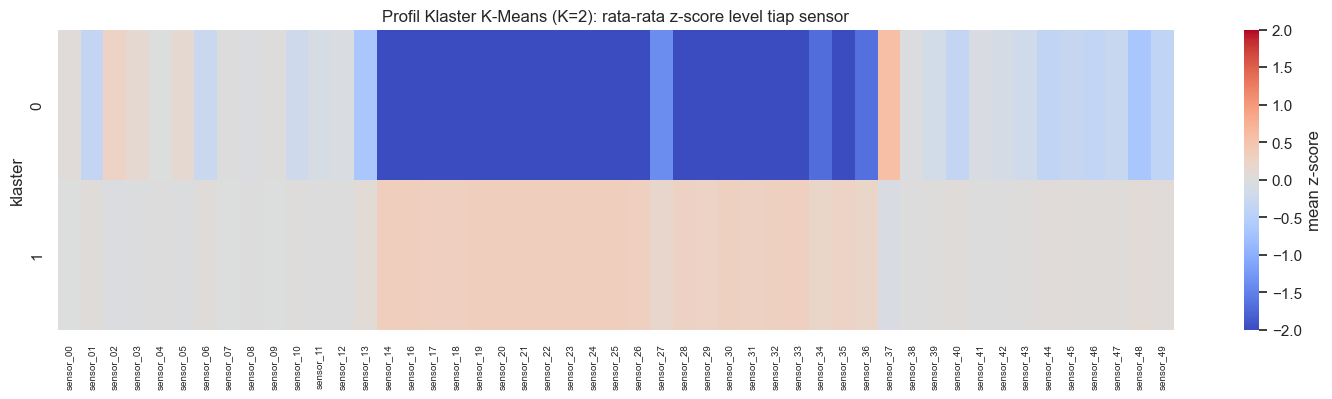

In [16]:
mean_z = pd.DataFrame(StandardScaler().fit_transform(F[mean_cols]),
                      columns=[c.split("__")[0] for c in mean_cols])
profile = mean_z.groupby(lab_km).mean()

plt.figure(figsize=(18, 0.7 * K_KMEANS + 2.5))
sns.heatmap(profile, cmap="coolwarm", center=0, vmin=-2, vmax=2, cbar_kws={"label": "mean z-score"})
plt.title(f"Profil Klaster K-Means (K={K_KMEANS}): rata-rata z-score level tiap sensor"); plt.ylabel("klaster"); plt.xticks(fontsize=7)
plt.show()

size = pd.DataFrame({"jumlah_window": np.bincount(lab_km)})
size["persen"] = (size["jumlah_window"] / size["jumlah_window"].sum() * 100).round(1)
size["sensor_pembeda_utama"] = [", ".join(profile.loc[k].abs().nlargest(4).index) for k in range(K_KMEANS)]
print("Ukuran cluster K-Means:")
display(size)

gmm_size = pd.DataFrame({"jumlah_window": np.bincount(lab_gm, minlength=K_GMM)})
gmm_size["persen"] = (gmm_size["jumlah_window"] / len(lab_gm) * 100).round(1)
print("Ukuran cluster GMM:")
display(gmm_size)
print("Cluster <5% K-Means:", size.index[size["persen"] < 5].tolist())
print("Cluster <5% GMM:", gmm_size.index[gmm_size["persen"] < 5].tolist())
size

## 14. Uji Sensitivitas Window dan Overlap\n
K-Means diuji pada beberapa kombinasi durasi dan stride dengan K tetap dari pemilihan baseline. Ini mengukur apakah kualitas cluster dan persistensi berubah besar ketika window/overlap berubah. Perbandingan ini bukan bukti otomatis bahwa skor tertinggi adalah pilihan paling bermakna secara operasional.

In [17]:
WINDOW_SCENARIOS = [(30, 15), (60, 30), (60, 60), (120, 60)]
sens_rows = []
for win, stride in WINDOW_SCENARIOS:
    F_s, meta_s = extract_windows(X, seg, win, stride)
    cols_s = [f"{sensor}__{stat}" for stat in FEATURE_STATS for sensor in sensor_cols]
    Fm_s = F_s[cols_s]
    Fm_s = Fm_s.loc[:, Fm_s.std() > 0]
    Zs = scale(Fm_s, SCALER, CLIP)
    cum_s = np.cumsum(PCA(random_state=RANDOM_STATE).fit(Zs).explained_variance_ratio_)
    n_pc = int(np.argmax(cum_s >= PCA_VARIANCE) + 1)
    Zs = PCA(n_components=n_pc, random_state=RANDOM_STATE).fit_transform(Zs)
    lab_s = KMeans(K_KMEANS, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(Zs)
    # Persistence dihitung hanya di dalam segmen, tanpa menyambung gap waktu.
    same_parts = []
    for sid in meta_s["segment"].unique():
        labels_sid = lab_s[meta_s["segment"].values == sid]
        if len(labels_sid) > 1:
            same_parts.append(labels_sid[1:] == labels_sid[:-1])
    pers = np.concatenate(same_parts).mean() if same_parts else np.nan
    sizes = np.bincount(lab_s, minlength=K_KMEANS) / len(lab_s)
    sens_rows.append({"window_menit":win,"stride_menit":stride,"jumlah_window":len(F_s),"PC_90%":n_pc,
                      "Silhouette_sampel":silhouette_sample(Zs,lab_s),"Davies_Bouldin":davies_bouldin_score(Zs,lab_s),
                      "persistensi":pers,"ukuran_cluster_min_%":sizes.min()*100})
window_sensitivity = pd.DataFrame(sens_rows)
display(window_sensitivity.round(3))


   window_menit  stride_menit  ...  persistensi  ukuran_cluster_min_%
0            30            15  ...        0.998                10.995
1            60            30  ...        0.997                11.082
2            60            60  ...        0.994                10.974
3           120            60  ...        0.994                11.341

[4 rows x 8 columns]


## 13. Simpan Hasil

In [18]:
out = meta.copy()
out["kmeans"] = lab_km
out["gmm"] = lab_gm
out["gmm_confidence"] = conf_gm.round(4)
cluster_path = OUTPUT_DIR / "hasil_klaster.csv"
metric_path = OUTPUT_DIR / "ringkasan_metrik.csv"
out.to_csv(cluster_path, index=False)
res.round(4).to_csv(metric_path)
print(f"Tersimpan di folder output Tahap 3:\n- {cluster_path.resolve()}\n- {metric_path.resolve()}")
out.head()

Tersimpan: C:\KULIAH\SEMESTER 5\Data mining\UTS Data Mining\Dataset\hasil_klaster.csv dan C:\KULIAH\SEMESTER 5\Data mining\UTS Data Mining\Dataset\ringkasan_metrik.csv


   segment               start                 end  kmeans  gmm  gmm_confidence
0        0 2018-04-01 00:00:00 2018-04-01 00:59:00       1    0             1.0
1        0 2018-04-01 00:30:00 2018-04-01 01:29:00       1    0             1.0
2        0 2018-04-01 01:00:00 2018-04-01 01:59:00       1    0             1.0
3        0 2018-04-01 01:30:00 2018-04-01 02:29:00       1    0             1.0
4        0 2018-04-01 02:00:00 2018-04-01 02:59:00       1    0             1.0

## 14. Ringkasan Rancangan untuk Paper (Bab II)
**Pipeline:** data bersih (49 sensor) → window 60 menit, stride 30 menit, dalam segmen kontinu → statistik window per sensor (mean dan std, dipilih lewat ablasi dari 5 kandidat) → scaling (StandardScaler + winsorizing ±5) → PCA (variansi ≥ 90%) → K-Means dan GMM dengan K dipilih terpisah.

**Optimasi hiperparameter:** $k$ lewat Elbow dan konsensus peringkat Silhouette/DBI/CH untuk K-Means; BIC scan untuk jumlah komponen dan tipe kovarians GMM; bila minimum berada di batas, K GMM dinyatakan belum konklusif dan same-K hanya dipakai sebagai pembanding; jumlah komponen PCA lewat ambang variansi kumulatif; himpunan fitur window dan scaler lewat perbandingan Silhouette.

**Evaluasi internal:** Silhouette Coefficient, Davies-Bouldin Index, Calinski-Harabasz Index, BIC, stabilitas antar-inisialisasi (ARI), persistensi temporal klaster dan uji sensitivitas window/stride.

**Keterbatasan yang jujur dicantumkan:** (1) label status ditahan dari fitting sehingga evaluasi utama bersifat internal; (2) window berimpit membuat observasi saling bergantung dan dapat menaikkan BIC/persistensi; (3) fitur window merangkum temporal lokal, bukan memodelkan urutan antar-window seperti HMM/LSTM; (4) makna operasional klaster perlu validasi pakar domain.